In [1]:
import numpy as np
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("covid_19_clean_complete.csv")
df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [5]:
df.shape

(49068, 10)

In [6]:
df.columns

Index(['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed',
       'Deaths', 'Recovered', 'Active', 'WHO Region'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB


In [8]:
df.describe()

,Lat,Long,Confirmed,Deaths,Recovered,Active
count,49068.000000,49068.000000,4.906800e+04,49068.000000,4.906800e+04,4.906800e+04
mean,21.433730,23.528236,1.688490e+04,884.179160,7.915713e+03,8.085012e+03
std,24.950320,70.442740,1.273002e+05,6313.584411,5.480092e+04,7.625890e+04
min,-51.796300,-135.000000,0.000000e+00,0.000000,0.000000e+00,-1.400000e+01
25%,7.873054,-15.310100,4.000000e+00,0.000000,0.000000e+00,0.000000e+00
50%,23.634500,21.745300,1.680000e+02,2.000000,2.900000e+01,2.600000e+01
75%,41.204380,80.771797,1.518250e+03,30.000000,6.660000e+02,6.060000e+02
max,71.706900,178.065000,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06


In [10]:
##checking missing values
df.isnull().sum()

Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                  0
Confirmed             0
Deaths                0
Recovered             0
Active                0
WHO Region            0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["Date"] = pd.to_datetime(df["Date"])

In [13]:
df["Date"].dtype

dtype('<M8[ns]')

In [14]:
df[["Confirmed", "Deaths", "Recovered", "Active"]].min()

Confirmed     0
Deaths        0
Recovered     0
Active      -14
dtype: int64

In [15]:
df[df["Active"] < 0]

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
16238,Hainan,China,19.195900,109.745300,2020-03-24,168,6,168,-6,Western Pacific
16499,Hainan,China,19.195900,109.745300,2020-03-25,168,6,168,-6,Western Pacific
16760,Hainan,China,19.195900,109.745300,2020-03-26,168,6,168,-6,Western Pacific
17021,Hainan,China,19.195900,109.745300,2020-03-27,168,6,168,-6,Western Pacific
17282,Hainan,China,19.195900,109.745300,2020-03-28,168,6,168,-6,Western Pacific
17543,Hainan,China,19.195900,109.745300,2020-03-29,168,6,168,-6,Western Pacific
17804,Hainan,China,19.195900,109.745300,2020-03-30,168,6,168,-6,Western Pacific
18065,Hainan,China,19.195900,109.745300,2020-03-31,168,6,168,-6,Western Pacific
18326,Hainan,China,19.195900,109.745300,2020-04-01,168,6,168,-6,Western Pacific
32059,Channel Islands,United Kingdom,49.372300,-2.364400,2020-05-23,558,45,515,-2,Europe


In [16]:
(df["Active"] < 0).sum()

np.int64(18)

In [17]:
(df["Active"] != (df["Confirmed"] - df["Deaths"] - df["Recovered"])).sum()

np.int64(0)

In [18]:
df["Active_Cleaned"] = df["Active"].clip(lower=0)

In [19]:
(df["Active_Cleaned"] < 0).sum()

np.int64(0)

In [20]:
df["Data_Quality_Flag"] = np.where(
    df["Active"] < 0,
    "Anomaly",
    "Valid"
)

In [21]:
df["Data_Quality_Flag"].value_counts()

Data_Quality_Flag
Valid      49050
Anomaly       18
Name: count, dtype: int64

In [22]:
print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())

Start Date: 2020-01-22 00:00:00
End Date: 2020-07-27 00:00:00


In [23]:
print("Total Countries/Regions:", df["Country/Region"].nunique())

print("WHO Regions:", df["WHO Region"].unique())

Total Countries/Regions: 187
WHO Regions: ['Eastern Mediterranean' 'Europe' 'Africa' 'Americas' 'Western Pacific'
 'South-East Asia']


In [24]:
latest_date = df["Date"].max()
print(latest_date)

2020-07-27 00:00:00


In [25]:
latest_df=df[df["Date"]==latest_date]
latest_df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region,Active_Cleaned,Data_Quality_Flag
48807,NaN,Afghanistan,33.93911,67.709953,2020-07-27,36263,1269,25198,9796,Eastern Mediterranean,9796,Valid
48808,NaN,Albania,41.15330,20.168300,2020-07-27,4880,144,2745,1991,Europe,1991,Valid
48809,NaN,Algeria,28.03390,1.659600,2020-07-27,27973,1163,18837,7973,Africa,7973,Valid
48810,NaN,Andorra,42.50630,1.521800,2020-07-27,907,52,803,52,Europe,52,Valid
48811,NaN,Angola,-11.20270,17.873900,2020-07-27,950,41,242,667,Africa,667,Valid


In [26]:
total_confirmed = latest_df["Confirmed"].sum()
total_deaths = latest_df["Deaths"].sum()
total_recovered = latest_df["Recovered"].sum()
total_active = latest_df["Active"].sum()

print("Total Confirmed:", total_confirmed)
print("Total Deaths:", total_deaths)
print("Total Recovered:", total_recovered)
print("Total Active:", total_active)

Total Confirmed: 16480485
Total Deaths: 654036
Total Recovered: 9468087
Total Active: 6358362


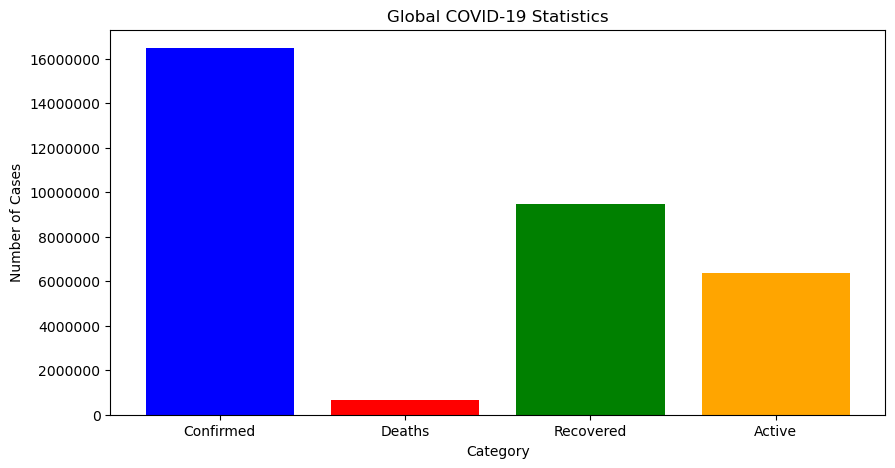

In [27]:
categories = ["Confirmed", "Deaths", "Recovered", "Active"]

values = [
    total_confirmed,
    total_deaths,
    total_recovered,
    total_active
]

plt.figure(figsize=(10, 5))

plt.bar(categories, values,
        color=["blue", "red", "green", "orange"])

plt.title("Global COVID-19 Statistics")
plt.xlabel("Category")
plt.ylabel("Number of Cases")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

Mortality rate among confirmed cases:
\[
\frac{\text{Total Deaths}}{\text{Total Confirmed}}\times100
\]


Recovery rate:
\[
\frac{\text{Total Recovered}}{\text{Total Confirmed}}\times100
\]

In [28]:
mortality_rate = (total_deaths / total_confirmed) * 100

recovery_rate = (total_recovered / total_confirmed) * 100

print("Mortality Rate:", round(mortality_rate, 2), "%")
print("Recovery Rate:", round(recovery_rate, 2), "%")

Mortality Rate: 3.97 %
Recovery Rate: 57.45 %


In [29]:
country_wise = latest_df.groupby("Country/Region")[
    ["Confirmed", "Deaths", "Recovered", "Active"]
].sum()

country_wise.head()

,Confirmed,Deaths,Recovered,Active
Country/Region,,,,
Afghanistan,36263,1269,25198,9796
Albania,4880,144,2745,1991
Algeria,27973,1163,18837,7973
Andorra,907,52,803,52
Angola,950,41,242,667


In [30]:
top_10 = country_wise.sort_values(
    by="Confirmed", ascending=False
).head(10)

top_10

,Confirmed,Deaths,Recovered,Active
Country/Region,,,,
US,4290259,148011,1325804,2816444
Brazil,2442375,87618,1846641,508116
India,1480073,33408,951166,495499
Russia,816680,13334,602249,201097
South Africa,452529,7067,274925,170537
Mexico,395489,44022,303810,47657
Peru,389717,18418,272547,98752
Chile,347923,9187,319954,18782
United Kingdom,301708,45844,1437,254427


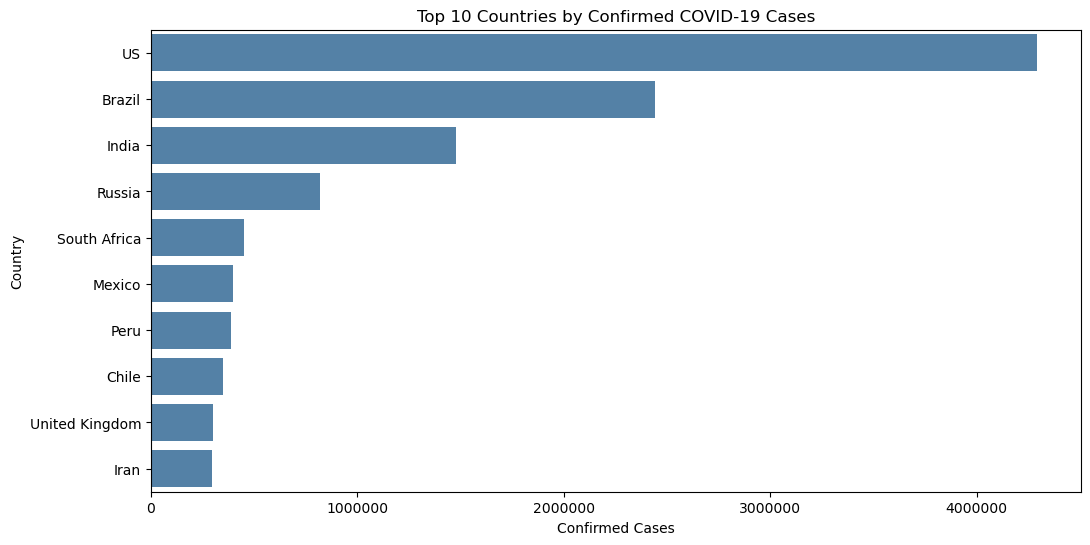

In [31]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10["Confirmed"],
    y=top_10.index,
    color="steelblue"
)

plt.title("Top 10 Countries by Confirmed COVID-19 Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("Country")
plt.ticklabel_format(style="plain", axis="x")
plt.show()

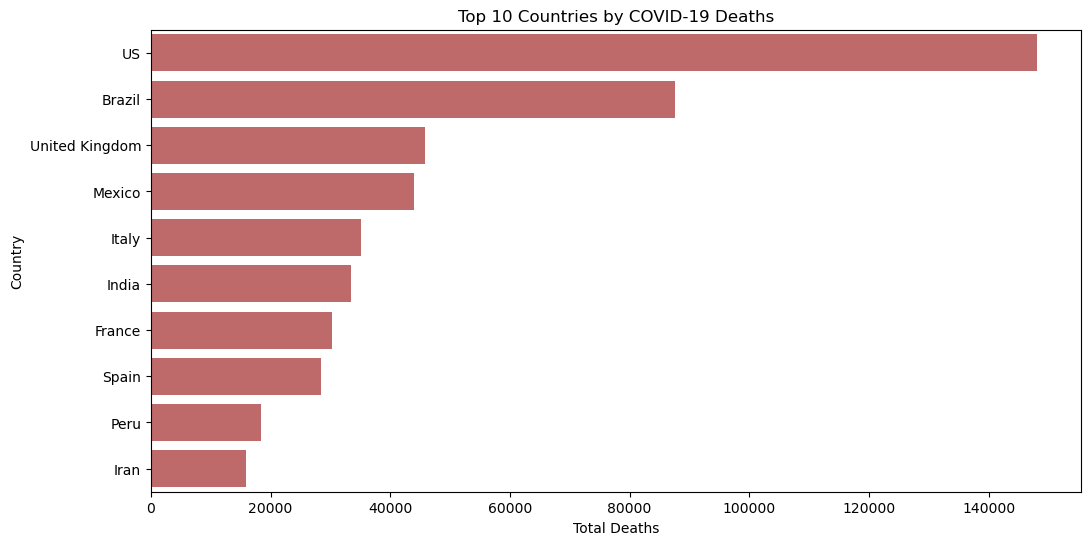

In [32]:
top_deaths = country_wise.sort_values(
    by="Deaths", ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_deaths["Deaths"],
    y=top_deaths.index,
    color="indianred"
)

plt.title("Top 10 Countries by COVID-19 Deaths")
plt.xlabel("Total Deaths")
plt.ylabel("Country")
plt.show()

In [33]:
country_wise["Recovery_Rate"] = (
    country_wise["Recovered"] /
    country_wise["Confirmed"].replace(0, np.nan)
) * 100

country_wise["Fatality_Rate"] = (
    country_wise["Deaths"] /
    country_wise["Confirmed"].replace(0, np.nan)
) * 100

country_wise.head()

,Confirmed,Deaths,Recovered,Active,Recovery_Rate,Fatality_Rate
Country/Region,,,,,,
Afghanistan,36263,1269,25198,9796,69.486805,3.499435
Albania,4880,144,2745,1991,56.250000,2.950820
Algeria,27973,1163,18837,7973,67.339935,4.157581
Andorra,907,52,803,52,88.533627,5.733186
Angola,950,41,242,667,25.473684,4.315789


In [34]:
country_wise.loc["India"]

Confirmed        1.480073e+06
Deaths           3.340800e+04
Recovered        9.511660e+05
Active           4.954990e+05
Recovery_Rate    6.426480e+01
Fatality_Rate    2.257186e+00
Name: India, dtype: float64

In [35]:
pd.set_option("display.float_format", "{:,.2f}".format)

country_wise.loc["India"]

Confirmed       1,480,073.00
Deaths             33,408.00
Recovered         951,166.00
Active            495,499.00
Recovery_Rate          64.26
Fatality_Rate           2.26
Name: India, dtype: float64

In [36]:
##Time Series Analysis

In [37]:
daily_data = df.groupby("Date")[
    ["Confirmed", "Deaths", "Recovered", "Active"]
].sum()

daily_data.head()

,Confirmed,Deaths,Recovered,Active
Date,,,,
2020-01-22,555,17,28,510
2020-01-23,654,18,30,606
2020-01-24,941,26,36,879
2020-01-25,1434,42,39,1353
2020-01-26,2118,56,52,2010


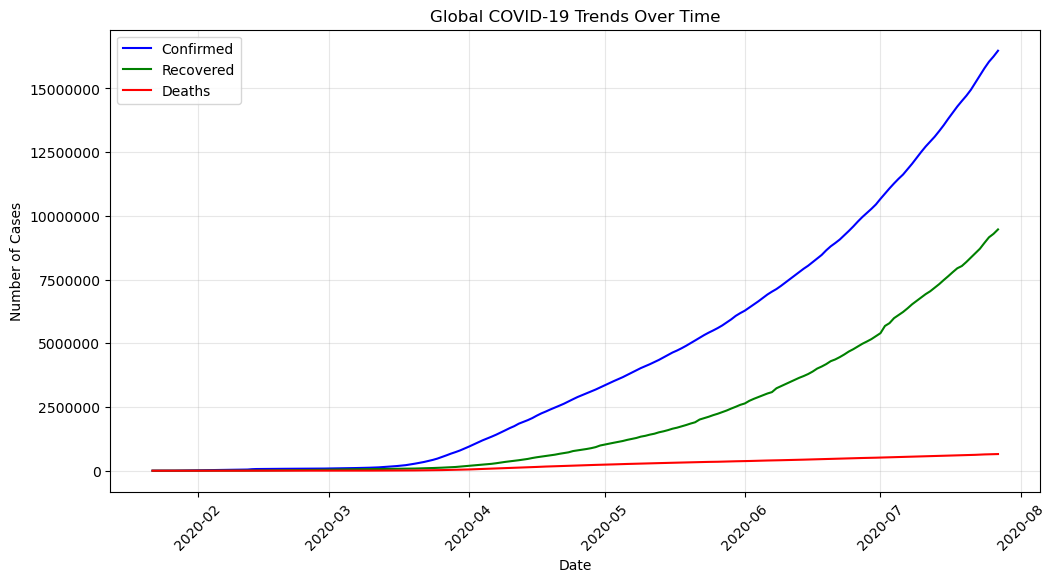

In [38]:
plt.figure(figsize=(12, 6))

plt.plot(daily_data.index,
         daily_data["Confirmed"],
         label="Confirmed", color="blue")

plt.plot(daily_data.index,
         daily_data["Recovered"],
         label="Recovered", color="green")

plt.plot(daily_data.index,
         daily_data["Deaths"],
         label="Deaths", color="red")

plt.title("Global COVID-19 Trends Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Cases")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [39]:
daily_data["New_Cases"] = daily_data["Confirmed"].diff()

daily_data["New_Deaths"] = daily_data["Deaths"].diff()

daily_data["New_Recovered"] = daily_data["Recovered"].diff()

daily_data.head()

,Confirmed,Deaths,Recovered,Active,New_Cases,New_Deaths,New_Recovered
Date,,,,,,,
2020-01-22,555,17,28,510,NaN,NaN,NaN
2020-01-23,654,18,30,606,99.00,1.00,2.00
2020-01-24,941,26,36,879,287.00,8.00,6.00
2020-01-25,1434,42,39,1353,493.00,16.00,3.00
2020-01-26,2118,56,52,2010,684.00,14.00,13.00


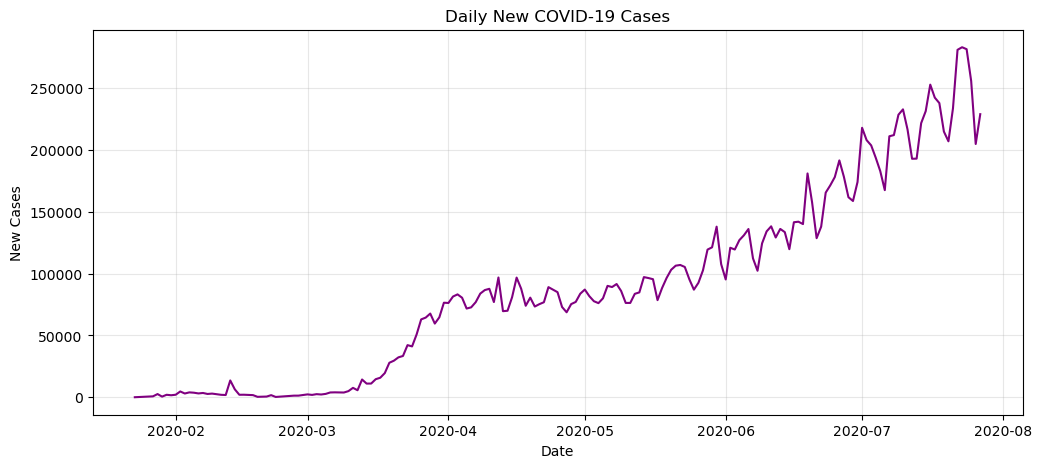

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(daily_data.index,
         daily_data["New_Cases"],
         color="purple")

plt.title("Daily New COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("New Cases")
plt.grid(alpha=0.3)
plt.show()

In [41]:
print("Peak Date:", daily_data["New_Cases"].idxmax())

print("Maximum New Cases:", daily_data["New_Cases"].max())

Peak Date: 2020-07-23 00:00:00
Maximum New Cases: 282756.0


In [42]:
india = df[df["Country/Region"] == "India"]

us = df[df["Country/Region"] == "US"]

In [43]:
india_daily = india.groupby("Date")["Confirmed"].sum()

us_daily = us.groupby("Date")["Confirmed"].sum()

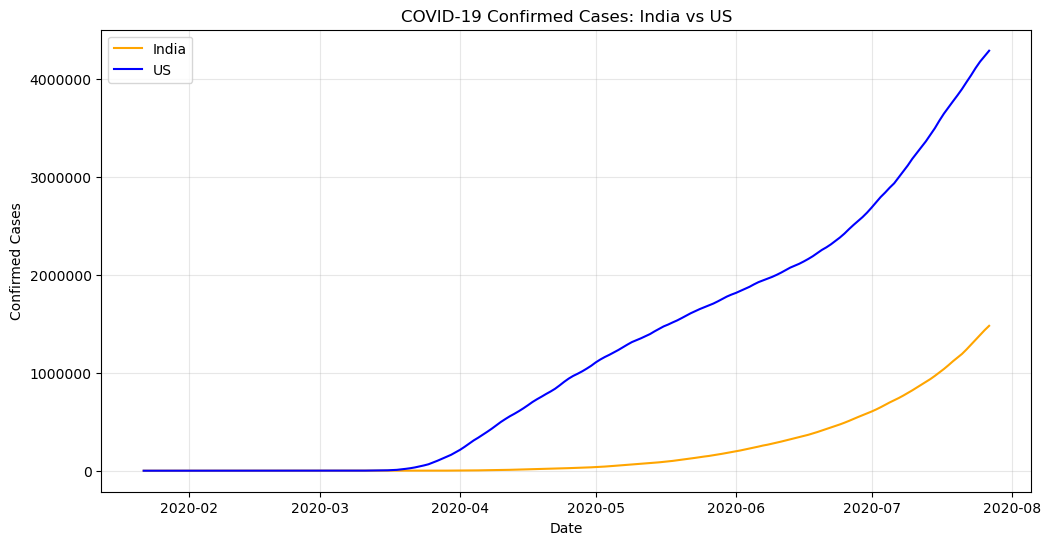

In [44]:
plt.figure(figsize=(12, 6))

plt.plot(india_daily.index, india_daily.values,
         label="India", color="orange")

plt.plot(us_daily.index, us_daily.values,
         label="US", color="blue")

plt.title("COVID-19 Confirmed Cases: India vs US")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.legend()
plt.grid(alpha=0.3)
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [45]:
monthly_data = daily_data["New_Cases"].resample("MS").sum()

monthly_data

Date
2020-01-01       9,372.00
2020-02-01      75,379.00
2020-03-01     786,049.00
2020-04-01   2,397,521.00
2020-05-01   2,916,654.00
2020-06-01   4,264,167.00
2020-07-01   6,030,788.00
Freq: MS, Name: New_Cases, dtype: float64

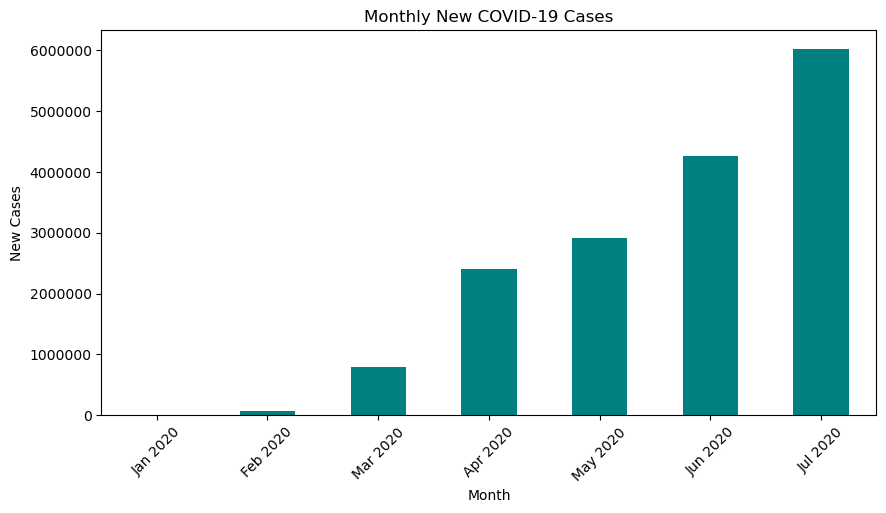

In [46]:
plt.figure(figsize=(10, 5))

monthly_data.plot(kind="bar", color="teal")

plt.title("Monthly New COVID-19 Cases")
plt.xlabel("Month")
plt.ylabel("New Cases")
plt.xticks(
    ticks=range(len(monthly_data)),
    labels=monthly_data.index.strftime("%b %Y"),
    rotation=45
)
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [47]:
region_wise = latest_df.groupby("WHO Region")[
    ["Confirmed", "Deaths", "Recovered"]
].sum()

region_wise

,Confirmed,Deaths,Recovered
WHO Region,,,
Africa,723207,12223,440645
Americas,8839286,342732,4468616
Eastern Mediterranean,1490744,38339,1201400
Europe,3299523,211144,1993723
South-East Asia,1835297,41349,1156933
Western Pacific,292428,8249,206770


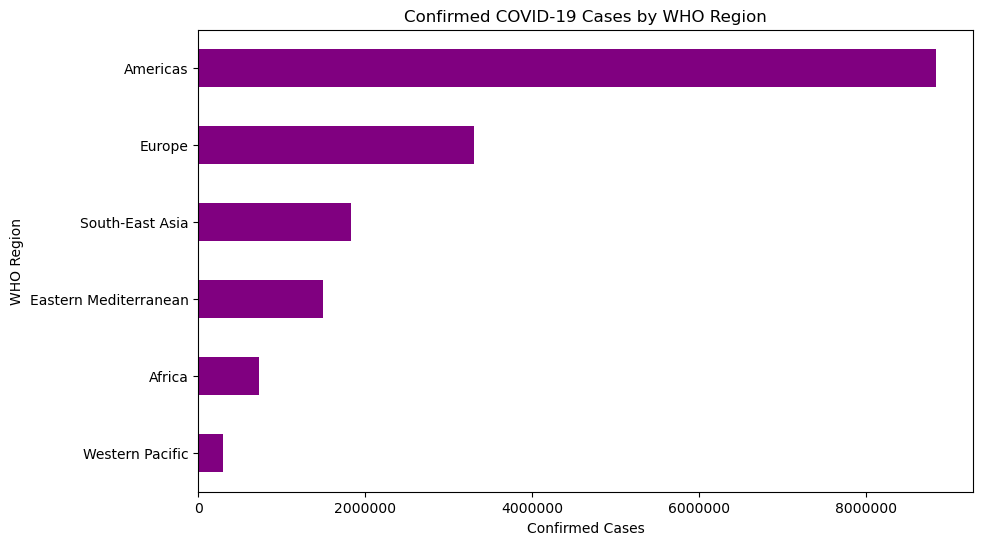

In [48]:
plt.figure(figsize=(10, 6))

region_wise["Confirmed"].sort_values().plot(
    kind="barh",
    color="purple"
)

plt.title("Confirmed COVID-19 Cases by WHO Region")
plt.xlabel("Confirmed Cases")
plt.ylabel("WHO Region")
plt.ticklabel_format(style="plain", axis="x")
plt.show()

In [49]:
correlation = country_wise[
    ["Confirmed", "Deaths", "Recovered", "Active"]
].corr()

correlation

,Confirmed,Deaths,Recovered,Active
Confirmed,1.00,0.93,0.91,0.93
Deaths,0.93,1.00,0.83,0.87
Recovered,0.91,0.83,1.00,0.68
Active,0.93,0.87,0.68,1.00


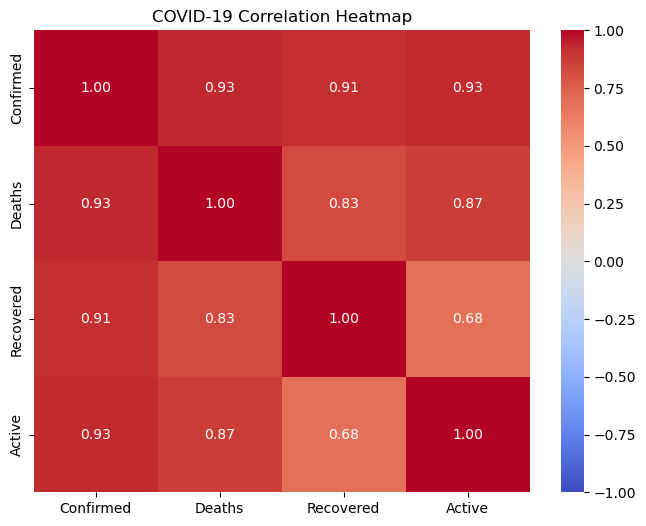

In [50]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("COVID-19 Correlation Heatmap")
plt.show()

In [51]:
df.to_csv("covid_cleaned_data.csv", index=False)

In [52]:
cleaned_df = pd.read_csv("covid_cleaned_data.csv")
cleaned_df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region,Active_Cleaned,Data_Quality_Flag
0,NaN,Afghanistan,33.94,67.71,2020-01-22,0,0,0,0,Eastern Mediterranean,0,Valid
1,NaN,Albania,41.15,20.17,2020-01-22,0,0,0,0,Europe,0,Valid
2,NaN,Algeria,28.03,1.66,2020-01-22,0,0,0,0,Africa,0,Valid
3,NaN,Andorra,42.51,1.52,2020-01-22,0,0,0,0,Europe,0,Valid
4,NaN,Angola,-11.20,17.87,2020-01-22,0,0,0,0,Africa,0,Valid


In [53]:
df.isnull().sum()

Province/State       34404
Country/Region           0
Lat                      0
Long                     0
Date                     0
Confirmed                0
Deaths                   0
Recovered                0
Active                   0
WHO Region               0
Active_Cleaned           0
Data_Quality_Flag        0
dtype: int64

In [54]:
df["Province/State"] = df["Province/State"].fillna("Not Specified")

In [55]:
df.to_csv("covid_cleaned_data.csv", index=False)

In [56]:
cleaned_df = pd.read_csv("covid_cleaned_data.csv")
cleaned_df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region,Active_Cleaned,Data_Quality_Flag
0,Not Specified,Afghanistan,33.94,67.71,2020-01-22,0,0,0,0,Eastern Mediterranean,0,Valid
1,Not Specified,Albania,41.15,20.17,2020-01-22,0,0,0,0,Europe,0,Valid
2,Not Specified,Algeria,28.03,1.66,2020-01-22,0,0,0,0,Africa,0,Valid
3,Not Specified,Andorra,42.51,1.52,2020-01-22,0,0,0,0,Europe,0,Valid
4,Not Specified,Angola,-11.20,17.87,2020-01-22,0,0,0,0,Africa,0,Valid
